# Notebook 3: Final Project: Cleaning, Analysis & Visualization
**Project:** Online Shopping Data Analysis

**Output:** a new file `shopping_data_cleaned.csv`

Keep `shopping_data.csv` in the same folder as this notebook.

In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
%matplotlib inline

## Step 1: Load the raw data

In [60]:
df = pd.read_csv("shopping_data.csv")
print("Raw shape:", df.shape)
df.head()

Raw shape: (255, 12)


,Order_ID,Order_Date,City,Product_Category,Payment_Mode,Customer_Type,Items_Count,Order_Value_INR,Discount_Percent,Delivery_Days,Browsing_Time_Min,Customer_Rating
0,ORD1063,2025-07-28,Mumbai,Beauty,Cash_on_Delivery,Prime,2,643.0,15,3.0,9.4,3.1
1,ORD1034,2026-03-30,Kolkata,Electronics,UPI,New,5,16744.0,21,3.0,18.4,3.5
2,ORD1029,2025-12-14,Lucknow,Electronics,UPI,Returning,1,1687.0,13,3.0,19.1,3.2
3,ORD1047,2026-08-12,Bengaluru,Electronics,Credit_Card,New,1,4224.0,5,2.0,9.9,3.2
4,ORD1175,2026-08-19,Delhi,Beauty,UPI,Returning,1,434.0,13,4.0,14.5,3.0


## Step 2: Check the problems

In [61]:
print("Missing values:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())
print()
print("Cities:", df["City"].unique())

Missing values:
Order_ID             0
Order_Date           0
City                 0
Product_Category     0
Payment_Mode         0
Customer_Type        5
Items_Count          0
Order_Value_INR      5
Discount_Percent     0
Delivery_Days        6
Browsing_Time_Min    4
Customer_Rating      0
dtype: int64

Duplicate rows: 5

Cities: <StringArray>
[   'Mumbai',   'Kolkata',   'Lucknow', 'Bengaluru',     'Delhi',   'LUCKNOW',
     'delhi', ' Kolkata ',   'kolkata',   'KOLKATA', 'Kolkata  ',   ' Mumbai']
Length: 12, dtype: str


## Step 3: Clean the data

In [62]:
clean = df.copy()

# 3.1 Remove duplicate rows
clean = clean.drop_duplicates()
print("After removing duplicates:", clean.shape)

After removing duplicates: (250, 12)


In [63]:
# 3.2 Fix City names: remove spaces, make consistent capitalisation
clean["City"] = clean["City"].str.strip().str.title()
print(clean["City"].value_counts())

City
Delhi        65
Bengaluru    55
Mumbai       53
Kolkata      47
Lucknow      30
Name: count, dtype: int64


In [64]:
# 3.3 Convert Order_Date to a real date
clean["Order_Date"] = pd.to_datetime(clean["Order_Date"])
clean.dtypes["Order_Date"]

dtype('<M8[us]')

In [65]:
# 3.4 Fix impossible discounts (below 0 or above 100) -> treat as missing, then fill with median
bad = (clean["Discount_Percent"] < 0) | (clean["Discount_Percent"] > 100)
print("Invalid discounts found:", bad.sum())
clean.loc[bad, "Discount_Percent"] = np.nan
clean["Discount_Percent"] = clean["Discount_Percent"].fillna(clean["Discount_Percent"].median())

Invalid discounts found: 2


In [66]:
# 3.5 Fill missing numeric values
# Order value: median of the same product category (more accurate than overall median)
clean["Order_Value_INR"] = clean.groupby("Product_Category")["Order_Value_INR"].transform(
    lambda s: s.fillna(s.median())
)
clean["Delivery_Days"] = clean["Delivery_Days"].fillna(clean["Delivery_Days"].median())
clean["Browsing_Time_Min"] = clean["Browsing_Time_Min"].fillna(clean["Browsing_Time_Min"].median())

# 3.6 Fill missing category values
clean["Customer_Type"] = clean["Customer_Type"].fillna("Unknown")

In [67]:
# 3.7 Fix data types
clean["Delivery_Days"] = clean["Delivery_Days"].astype(int)

In [68]:
# 3.8 Create new useful columns
clean["Order_Year"] = clean["Order_Date"].dt.year
clean["Order_Month"] = clean["Order_Date"].dt.month_name()
clean["Order_Month_Num"] = clean["Order_Date"].dt.month

clean["Value_Segment"] = pd.cut(
    clean["Order_Value_INR"],
    bins=[0, 1000, 5000, np.inf],
    labels=["Low", "Medium", "High"]
)

In [69]:
# 3.9 Flag outliers using the IQR rule (we keep them, just mark them)
q1, q3 = clean["Order_Value_INR"].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
clean["Is_Outlier"] = clean["Order_Value_INR"] > upper
print("Upper limit:", round(upper, 2), "| Outliers flagged:", clean["Is_Outlier"].sum())

Upper limit: 8672.75 | Outliers flagged: 30


## Step 4: Verify the cleaning

In [70]:
print("Cleaned shape:", clean.shape)
print("Missing values left:", clean.isnull().sum().sum())
print("Duplicates left:", clean.duplicated().sum())
clean.head()

Cleaned shape: (250, 17)
Missing values left: 0
Duplicates left: 0


,Order_ID,Order_Date,City,Product_Category,Payment_Mode,Customer_Type,Items_Count,Order_Value_INR,Discount_Percent,Delivery_Days,Browsing_Time_Min,Customer_Rating,Order_Year,Order_Month,Order_Month_Num,Value_Segment,Is_Outlier
0,ORD1063,2025-07-28,Mumbai,Beauty,Cash_on_Delivery,Prime,2,643.0,15.0,3,9.4,3.1,2025,July,7,Low,False
1,ORD1034,2026-03-30,Kolkata,Electronics,UPI,New,5,16744.0,21.0,3,18.4,3.5,2026,March,3,High,True
2,ORD1029,2025-12-14,Lucknow,Electronics,UPI,Returning,1,1687.0,13.0,3,19.1,3.2,2025,December,12,Medium,False
3,ORD1047,2026-08-12,Bengaluru,Electronics,Credit_Card,New,1,4224.0,5.0,2,9.9,3.2,2026,August,8,Medium,False
4,ORD1175,2026-08-19,Delhi,Beauty,UPI,Returning,1,434.0,13.0,4,14.5,3.0,2026,August,8,Low,False


## Step 5: Analysis

In [71]:
print("Total orders      :", len(clean))
print("Total revenue (INR):", round(clean["Order_Value_INR"].sum(), 2))
print("Average order value:", round(clean["Order_Value_INR"].mean(), 2))
print("Average rating     :", round(clean["Customer_Rating"].mean(), 2))

Total orders      : 250
Total revenue (INR): 925278.0
Average order value: 3701.11
Average rating     : 3.55


In [72]:
clean.groupby("Product_Category").agg(
    orders=("Order_ID", "count"),
    revenue=("Order_Value_INR", "sum"),
    avg_rating=("Customer_Rating", "mean")
).sort_values("revenue", ascending=False).round(2)

,orders,revenue,avg_rating
Product_Category,,,
Electronics,57,598126.5,3.42
Fashion,76,171427.0,3.55
Home_Kitchen,45,85862.5,3.65
Beauty,38,37226.0,3.60
Books,34,32636.0,3.55


In [73]:
clean.groupby("City")["Order_Value_INR"].agg(["count", "sum", "mean"]).round(2).sort_values("sum", ascending=False)

,count,sum,mean
City,,,
Mumbai,53,234432.0,4423.25
Bengaluru,55,216658.5,3939.25
Delhi,65,214757.5,3303.96
Kolkata,47,156397.5,3327.61
Lucknow,30,103032.5,3434.42


## Step 6: Visualizations

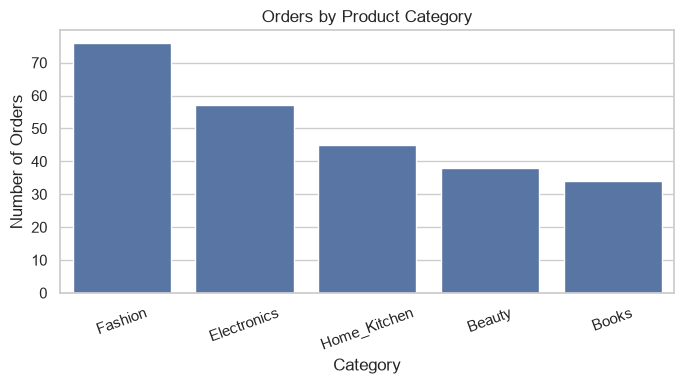

In [74]:
# 1. Orders per product category
plt.figure(figsize=(7, 4))
sns.countplot(data=clean, x="Product_Category", order=clean["Product_Category"].value_counts().index)
plt.title("Orders by Product Category")
plt.xlabel("Category"); plt.ylabel("Number of Orders")
plt.xticks(rotation=20)
plt.tight_layout(); plt.show()

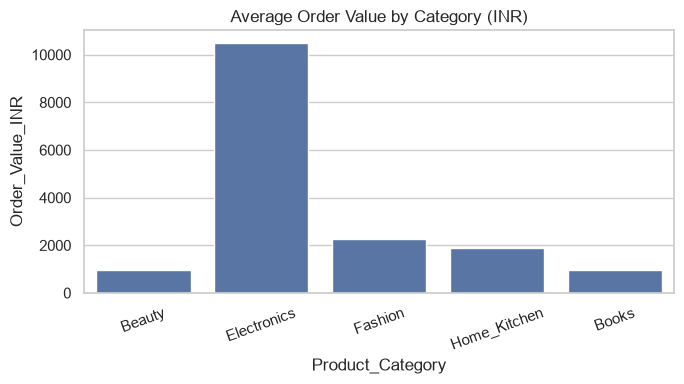

In [75]:
# 2. Average order value by category
plt.figure(figsize=(7, 4))
sns.barplot(data=clean, x="Product_Category", y="Order_Value_INR", estimator="mean", errorbar=None)
plt.title("Average Order Value by Category (INR)")
plt.xticks(rotation=20)
plt.tight_layout(); plt.show()

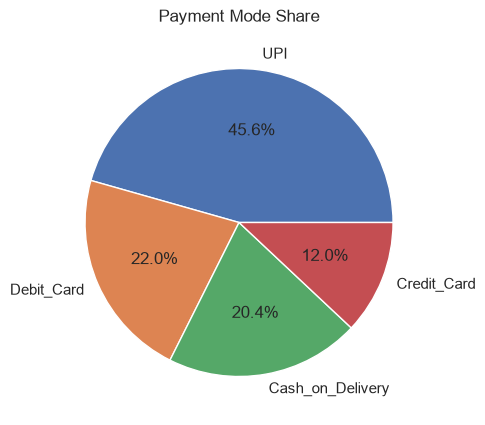

In [76]:
# 3. Payment mode share
clean["Payment_Mode"].value_counts().plot.pie(autopct="%1.1f%%", figsize=(5, 5))
plt.title("Payment Mode Share"); plt.ylabel("")
plt.show()

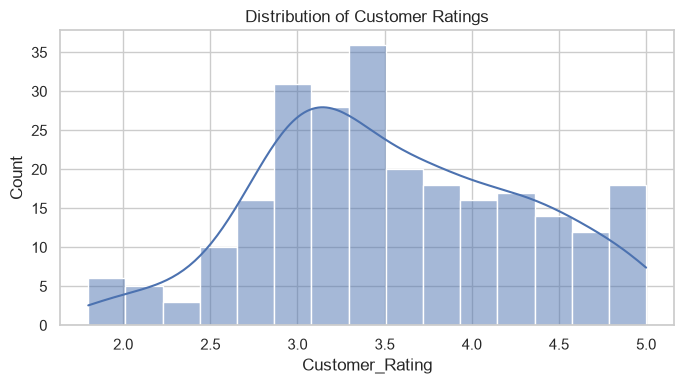

In [77]:
# 4. Distribution of customer ratings
plt.figure(figsize=(7, 4))
sns.histplot(clean["Customer_Rating"], bins=15, kde=True)
plt.title("Distribution of Customer Ratings")
plt.tight_layout(); plt.show()

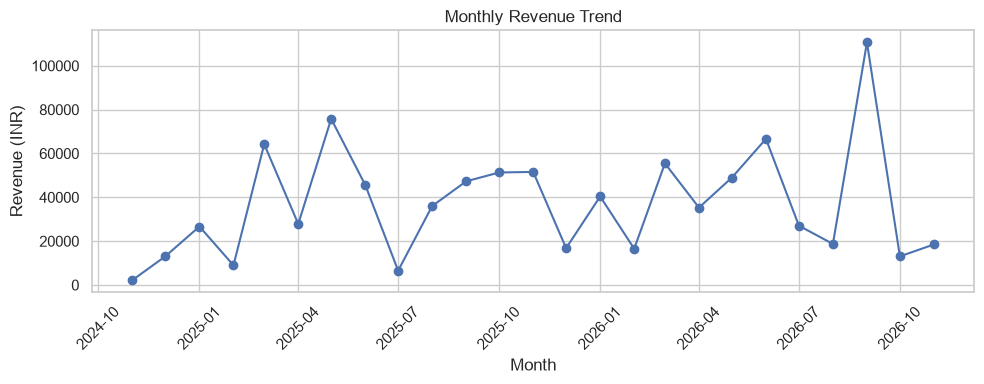

In [78]:
# 5. Monthly revenue trend
monthly = clean.groupby(clean["Order_Date"].dt.to_period("M"))["Order_Value_INR"].sum()
monthly.index = monthly.index.to_timestamp()
plt.figure(figsize=(10, 4))
plt.plot(monthly.index, monthly.values, marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month"); plt.ylabel("Revenue (INR)")
plt.xticks(rotation=45)
plt.tight_layout(); plt.show()

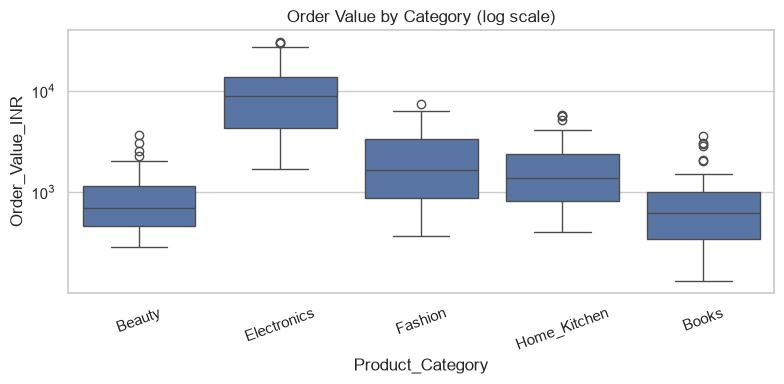

In [79]:
# 6. Boxplot: order value by category (log scale because of big outliers)
plt.figure(figsize=(8, 4))
sns.boxplot(data=clean, x="Product_Category", y="Order_Value_INR")
plt.yscale("log")
plt.title("Order Value by Category (log scale)")
plt.xticks(rotation=20)
plt.tight_layout(); plt.show()

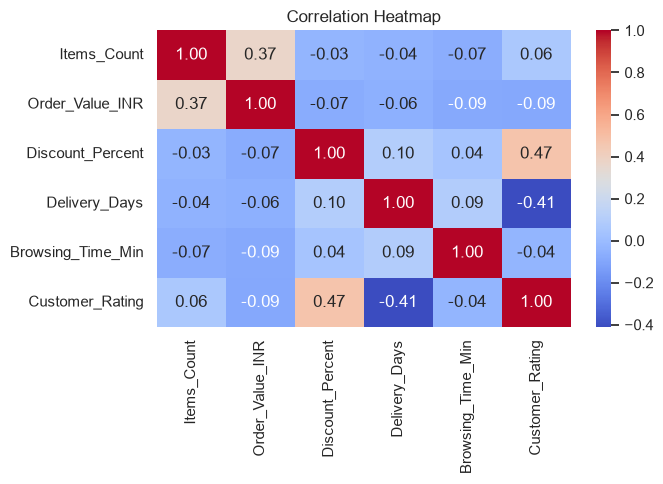

In [80]:
# 7. Correlation heatmap
num_cols = ["Items_Count", "Order_Value_INR", "Discount_Percent", "Delivery_Days", "Browsing_Time_Min", "Customer_Rating"]
plt.figure(figsize=(7, 5))
sns.heatmap(clean[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout(); plt.show()

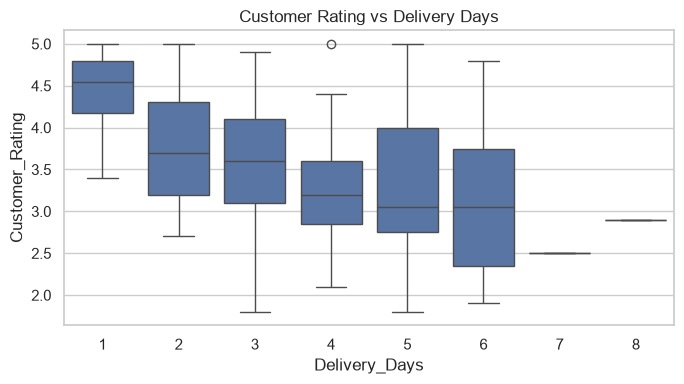

In [81]:
# 8. Does faster delivery mean better rating?
plt.figure(figsize=(7, 4))
sns.boxplot(data=clean, x="Delivery_Days", y="Customer_Rating")
plt.title("Customer Rating vs Delivery Days")
plt.tight_layout(); plt.show()

## Step 7: Save the cleaned file

In [82]:
clean.to_csv("shopping_data_cleaned.csv", index=False)
print("Saved: shopping_data_cleaned.csv")

Saved: shopping_data_cleaned.csv


In [83]:
# Check that the saved file is OK
check = pd.read_csv("shopping_data_cleaned.csv")
print(check.shape)
check.head()

(250, 17)


,Order_ID,Order_Date,City,Product_Category,Payment_Mode,Customer_Type,Items_Count,Order_Value_INR,Discount_Percent,Delivery_Days,Browsing_Time_Min,Customer_Rating,Order_Year,Order_Month,Order_Month_Num,Value_Segment,Is_Outlier
0,ORD1063,2025-07-28,Mumbai,Beauty,Cash_on_Delivery,Prime,2,643.0,15.0,3,9.4,3.1,2025,July,7,Low,False
1,ORD1034,2026-03-30,Kolkata,Electronics,UPI,New,5,16744.0,21.0,3,18.4,3.5,2026,March,3,High,True
2,ORD1029,2025-12-14,Lucknow,Electronics,UPI,Returning,1,1687.0,13.0,3,19.1,3.2,2025,December,12,Medium,False
3,ORD1047,2026-08-12,Bengaluru,Electronics,Credit_Card,New,1,4224.0,5.0,2,9.9,3.2,2026,August,8,Medium,False
4,ORD1175,2026-08-19,Delhi,Beauty,UPI,Returning,1,434.0,13.0,4,14.5,3.0,2026,August,8,Low,False


## Step 8: How to get (download) the cleaned file

**If you use Google Colab**, run the cell below. It downloads the file to your computer.
Or: click the folder icon on the left → right-click `shopping_data_cleaned.csv` → Download.

**If you use Jupyter Notebook / VS Code on your computer**, the file is already saved in the same folder as this notebook. No download needed.

In [84]:
try:
    from google.colab import files
    files.download("shopping_data_cleaned.csv")
except ImportError:
    import os
    print("Not running in Colab. File is saved here:")
    print(os.path.abspath("shopping_data_cleaned.csv"))

Not running in Colab. File is saved here:
c:\Users\User\OneDrive\Desktop\DATA_ANALYTICS_PROJECT\notebook\shopping_data_cleaned.csv


## Step 9: Key findings (write your own conclusions here)
- Which category earns the most revenue?
- Which city places the most orders?
- Which payment mode is most popular?
- Is there a link between delivery time and customer rating?